# Calculate the potential prognostic predictability

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import esm4ppe
import gfdl_utils as gu
from dask.diagnostics import ProgressBar
import xarray as xr
import pandas as pd

In [3]:
sorted(gu.core.get_allvars(esm4ppe.get_pp())['ocean_cobalt_omip_sfc'])

['baccos',
 'bfeos',
 'bsios',
 'chldiatos',
 'chldiazos',
 'chlmiscos',
 'chlos',
 'chlpicoos',
 'co3os',
 'co3sataragos',
 'co3satcalcos',
 'dfeos',
 'dissicos',
 'dissocos',
 'nh4os',
 'no3os',
 'o2os',
 'o2satos',
 'phos',
 'phycos',
 'phydiatos',
 'phydiazos',
 'phyfeos',
 'phymiscos',
 'phynos',
 'phypicoos',
 'phypos',
 'physios',
 'po4os',
 'ponos',
 'popos',
 'sios',
 'talkos',
 'zmesoos',
 'zmicroos',
 'zoocos']

In [4]:
variables = ['intpp']
frequency = 'monthly'

In [6]:
for variable in variables:
    print(variable)
    es = esm4ppe.esm4ppeObj(variable,frequency)
    # open the ensemble and the control, save to zarr, calculate ppp
    es = (
        es.add_ensemble(write=False).
        add_control(write=False).
        verify('acc',comparison='m2c',groupby='month',reference=["persistence","climatology"],dim=['member','init'],saveskill=False)
    )

intpp
Opening static... static opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Ensemble present in zarr store... opening... ensemble opened.
Control present in zarr store... opening...
control opened.
Calculating skill metric... ...skill metric calculated.


In [18]:
def convert_booleandictentries(dictionary):
    for key,value in dictionary.items():
        if type(value) is bool:
            dictionary[key]=int(value)
    return dictionary

PerfectModel_persistence_from_initialized_lead_0


In [87]:
es.ensemble.assign_coords({'init':pd.DatetimeIndex(es.ensemble.init.values)})

TypeError: <class 'cftime._cftime.DatetimeNoLeap'> is not convertible to datetime, at position 0

In [2]:
import climpred
# es.control["time"].attrs["units"] = "months"
# pm = climpred.PerfectModelEnsemble(es.ensemble).add_control(es.control.chunk({'time':-1}))


In [5]:
# initialized = climpred.tutorial.load_dataset(
#     "CESM-DP-SST"
# )  # CESM-DPLE hindcast ensemble output.
obs = climpred.tutorial.load_dataset("ERSST")

URLError: <urlopen error [Errno -2] Name or service not known>

In [6]:
climpred.tutorial.load_dataset("MPI-PM-DP-1D")

<xarray.Dataset>
Dimensions:  (period: 5, lead: 20, area: 3, init: 12, member: 10)
Coordinates:
  * lead     (lead) int64 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20
  * period   (period) <U3 'DJF' 'JJA' 'MAM' 'SON' 'ym'
  * area     (area) <U18 'global' 'North_Atlantic' 'North_Atlantic_SPG'
  * init     (init) int64 3014 3023 3045 3061 3124 ... 3175 3178 3228 3237 3257
  * member   (member) int64 0 1 2 3 4 5 6 7 8 9
Data variables:
    tos      (period, lead, area, init, member) float32 ...
    sos      (period, lead, area, init, member) float32 ...
    AMO      (period, lead, area, init, member) float32 ...

In [72]:
pm = pm.generate_uninitialized()
pm

ValueError: ('Please provide the same temporal resolution for verif.time', '(found day) and init.init (found', 'month).')

In [55]:
p = climpred.reference.compute_persistence(es.ensemble,es.control,metric='acc',comparison='m2c',dim=['init','member'],alignment='same_inits')

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:309: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


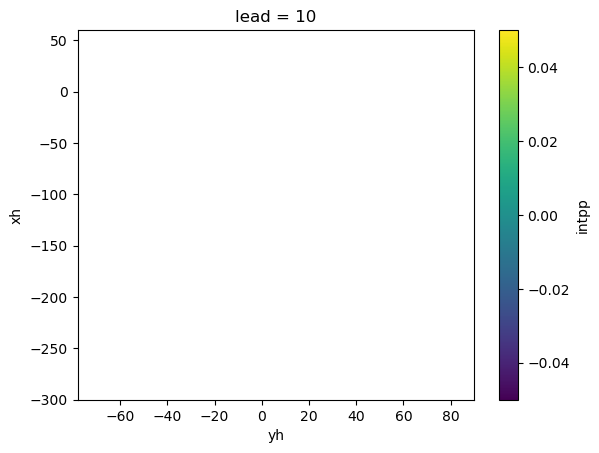

In [56]:
p['intpp'].sel(lead=10).plot()

In [14]:
acc = pm.verify(
    metric="acc",
    comparison="m2c",
    groupby="month",
    dim=["init", "member"],
    reference="persistence"
)

In [21]:
with ProgressBar():
    dsnow = acc.sel(month=1,xh=-150,yh=0,method='nearest').compute()

[#########                               ] | 24% Completed | 11.90 ss

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xskillscore/core/np_deterministic.py:309: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


[########################################] | 100% Completed | 64.91 s


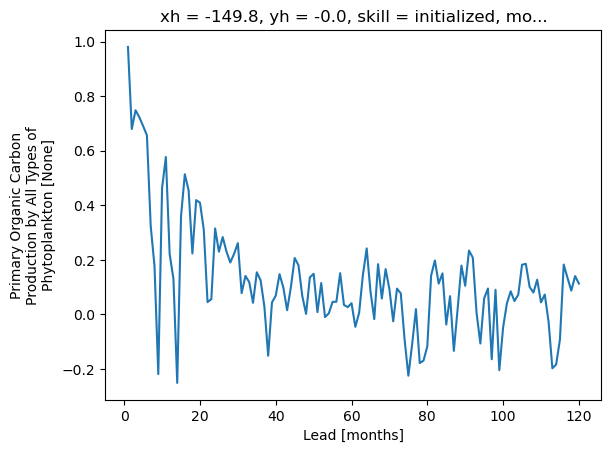

In [24]:
dsnow['intpp'].sel(skill='initialized').plot()

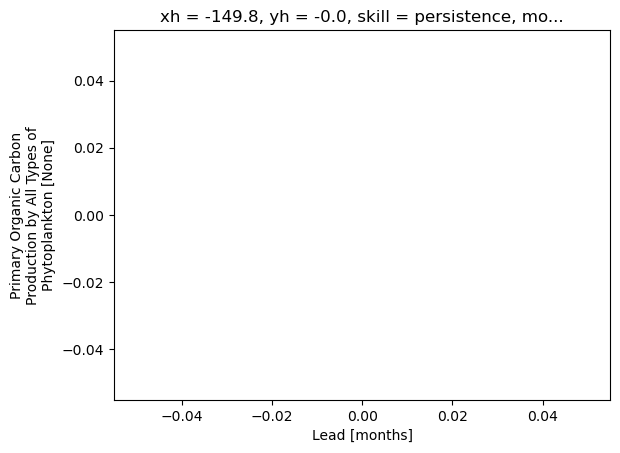

In [25]:
dsnow['intpp'].sel(skill='persistence').plot()